<a href="https://colab.research.google.com/github/FaganApriansyah/KKA-Fagan-Apriansyah/blob/main/Praktikum_Analisis_dan_Visualisasi_Data_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**KELOMPOK 2**
* Aurelya Ramadani/06
* Fagan Apriansyah/12
* Haidar Ali Yafi/17
* Raphael Ethan/28

In [ ]:
import pandas as pd
df = pd.read_csv('basket_details.csv')
print(df['basket_count'].mean()) # rata-rata
print(df['basket_count'].median()) # median
print(df['basket_count'].std()) # standar deviasi
print(df['basket_count'].quantile(0.25)) # Q1
print(df['basket_count'].quantile(0.75)) # Q3
print(df.describe()) # ringkasan statistik seluruh kolom numerik

2.1537333333333333
2.0
0.5179291575718746
2.0
2.0
        customer_id    product_id  basket_count
count  1.500000e+04  1.500000e+04  15000.000000
mean   1.808567e+07  3.269771e+07      2.153733
std    1.233000e+07  1.629455e+07      0.517929
min    4.784000e+03  4.939000e+04      2.000000
25%    8.659327e+06  3.137412e+07      2.000000
50%    1.520775e+07  3.694759e+07      2.000000
75%    2.663904e+07  4.502408e+07      2.000000
max    4.460824e+07  5.579097e+07     10.000000


In [ ]:
import pandas as pd

df = pd.read_csv('/content/basket_details.csv')

print(df.head()) # melihat 5 baris pertama
print(df.info()) # tipe data dan jumlah data kosong
print(df.describe()) # ringkasan statistik

print(df.isnull().sum()) # mengecek data kosong

# Statistik Basket Count
print("Mean:", df['basket_count'].mean()) # rata-rata
print("Median:", df['basket_count'].median()) # median
print("Standar Deviasi:", df['basket_count'].std()) # standar deviasi

print("Q1:", df['basket_count'].quantile(0.25)) # kuartil 1
print("Q3:", df['basket_count'].quantile(0.75)) # kuartil 3

print(df.describe()) # ringkasan statistik seluruh kolom numerik


   customer_id  product_id basket_date  basket_count
0     42366585    41475073  2019-06-19             2
1     35956841    43279538  2019-06-19             2
2     26139578    31715598  2019-06-19             3
3      3262253    47880260  2019-06-19             2
4     20056678    44747002  2019-06-19             2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   customer_id   15000 non-null  int64 
 1   product_id    15000 non-null  int64 
 2   basket_date   15000 non-null  object
 3   basket_count  15000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 468.9+ KB
None
        customer_id    product_id  basket_count
count  1.500000e+04  1.500000e+04  15000.000000
mean   1.808567e+07  3.269771e+07      2.153733
std    1.233000e+07  1.629455e+07      0.517929
min    4.784000e+03  4.939000e+04      2.000000
25%    8.659327e+06  3.13

Analisis: Dataset memiliki 15.000 baris data dan tidak terdapat data kosong. Rata-rata basket_count adalah 2,15, sedangkan mediannya 2. Artinya, jumlah basket paling banyak berada di sekitar 2.

/tmp/ipykernel_4112/3576196468.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_produk.values, y=total_produk.index.astype(str), palette='Blues_r')


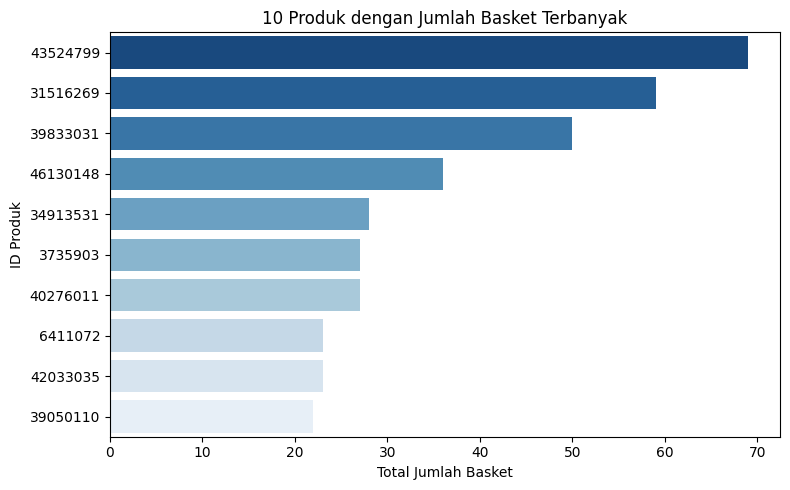

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

total_produk = df.groupby('product_id')['basket_count'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=total_produk.values, y=total_produk.index.astype(str), palette='Blues_r')

plt.title('10 Produk dengan Jumlah Basket Terbanyak')
plt.xlabel('Total Jumlah Basket')
plt.ylabel('ID Produk')

plt.tight_layout()
plt.show()


Analisis: Produk ID 43524799 merupakan produk dengan jumlah basket terbanyak. Hal ini menunjukkan bahwa produk tersebut memiliki jumlah pembelian atau pemesanan paling tinggi berdasarkan data. Informasi ini dapat digunakan untuk mengetahui produk yang paling banyak diminati pelanggan.

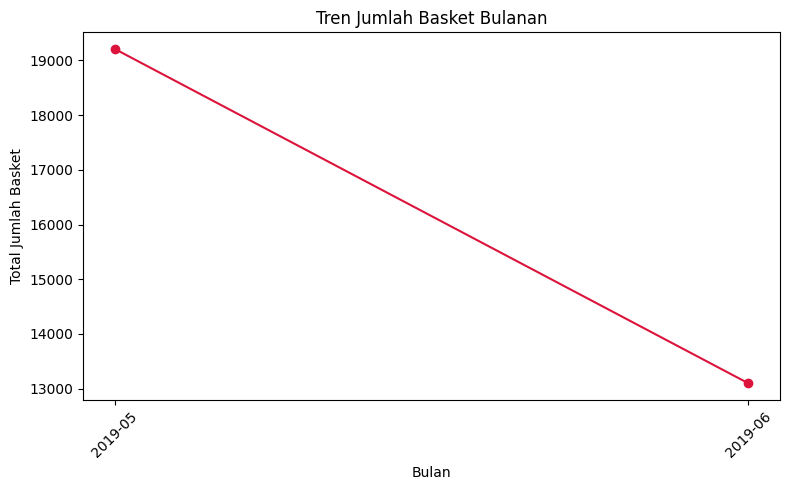

In [ ]:
df['basket_date'] = pd.to_datetime(df['basket_date'])
df['bulan'] = df['basket_date'].dt.to_period('M')

tren_bulanan = df.groupby('bulan')['basket_count'].sum()

plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')

plt.title('Tren Jumlah Basket Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Jumlah Basket')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Analisis: Jumlah basket mengalami penurunan dari sekitar 19.200 pada Mei 2019 menjadi 13.100 pada Juni 2019. Hal ini menunjukkan adanya penurunan aktivitas pembelian atau pemesanan pada bulan Juni.

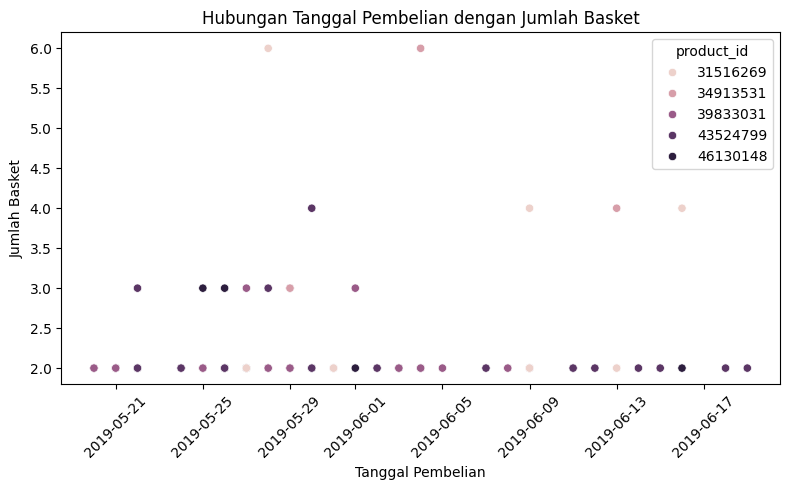

In [ ]:
df['basket_date'] = pd.to_datetime(df['basket_date'])

# Mengambil 5 produk dengan jumlah basket terbanyak
produk_teratas = df.groupby('product_id')['basket_count'].sum().nlargest(5).index

data_scatter = df[df['product_id'].isin(produk_teratas)]

plt.figure(figsize=(8,5))
sns.scatterplot(data=data_scatter, x='basket_date', y='basket_count', hue='product_id')

plt.title('Hubungan Tanggal Pembelian dengan Jumlah Basket')
plt.xlabel('Tanggal Pembelian')
plt.ylabel('Jumlah Basket')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Analisis: Grafik menunjukkan hubungan antara tanggal pembelian dengan jumlah basket pada 5 produk teratas. Setiap produk memiliki jumlah basket yang berbeda-beda pada tanggal pembelian tertentu. Informasi ini dapat digunakan untuk mengetahui pola pembelian produk dari waktu ke waktu.

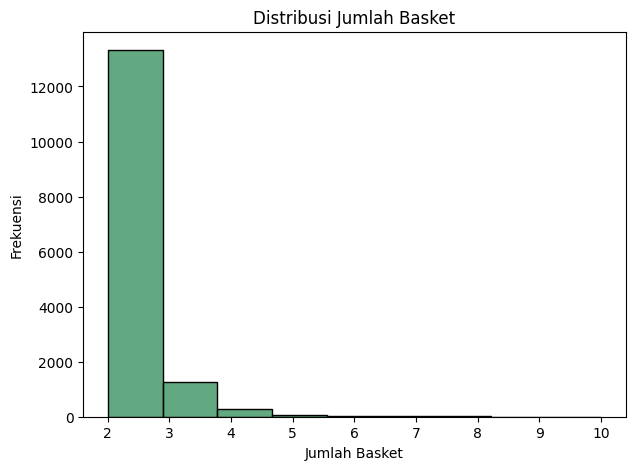

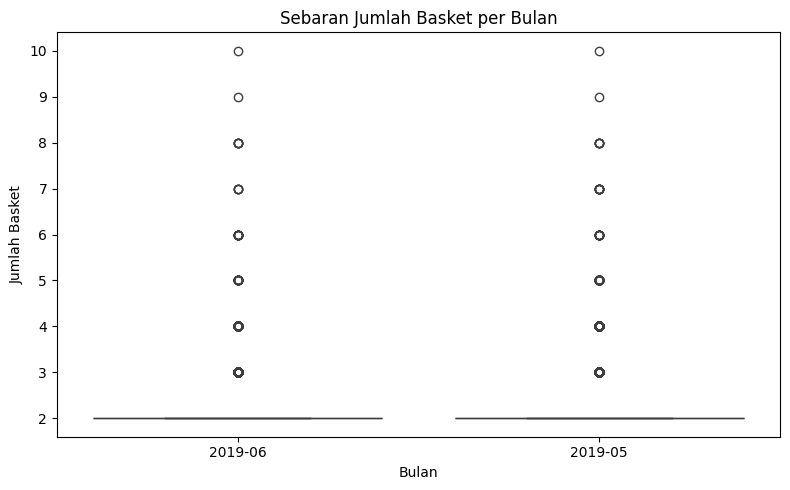

In [ ]:
# Histogram distribusi jumlah basket
plt.figure(figsize=(7,5))
sns.histplot(df['basket_count'], bins=9, color='seagreen')
plt.title('Distribusi Jumlah Basket')
plt.xlabel('Jumlah Basket')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot jumlah basket per bulan (deteksi outlier)
df['basket_date'] = pd.to_datetime(df['basket_date'])
df['bulan'] = df['basket_date'].dt.to_period('M').astype(str)

plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='bulan', y='basket_count')
plt.title('Sebaran Jumlah Basket per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Basket')
plt.tight_layout()
plt.show()


Analisis: Histogram menunjukkan bahwa jumlah basket paling banyak berada pada angka 2, sedangkan jumlah basket yang lebih tinggi memiliki frekuensi lebih sedikit. Boxplot menunjukkan adanya beberapa outlier pada bulan Mei dan Juni, yang menandakan terdapat transaksi dengan jumlah basket lebih tinggi dari biasanya.

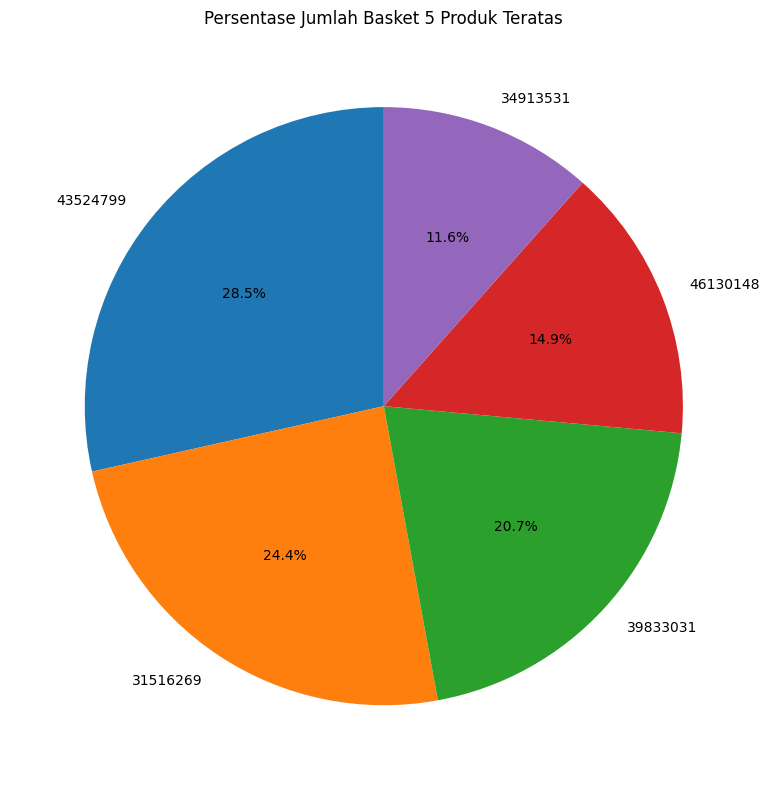

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Membaca data jika belum terdefinisi
try:
    df
except NameError:
    df = pd.read_csv('basket_details.csv')

# Menghitung jumlah basket berdasarkan produk
total_produk = df.groupby('product_id')['basket_count'].sum().nlargest(5)

plt.figure(figsize=(8,8))
plt.pie(
    total_produk.values,
    labels=total_produk.index.astype(str),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Persentase Jumlah Basket 5 Produk Teratas')
plt.tight_layout()
plt.show()

Analisis: Diagram menunjukkan persentase jumlah basket dari 5 produk teratas. Produk dengan ID 43524799 memiliki persentase tertinggi sebesar 28,5%, sedangkan produk dengan ID 34913531 memiliki persentase terendah sebesar 11,6%. Hal ini menunjukkan bahwa produk 43524799 memiliki kontribusi jumlah basket paling besar dibandingkan produk lainnya.

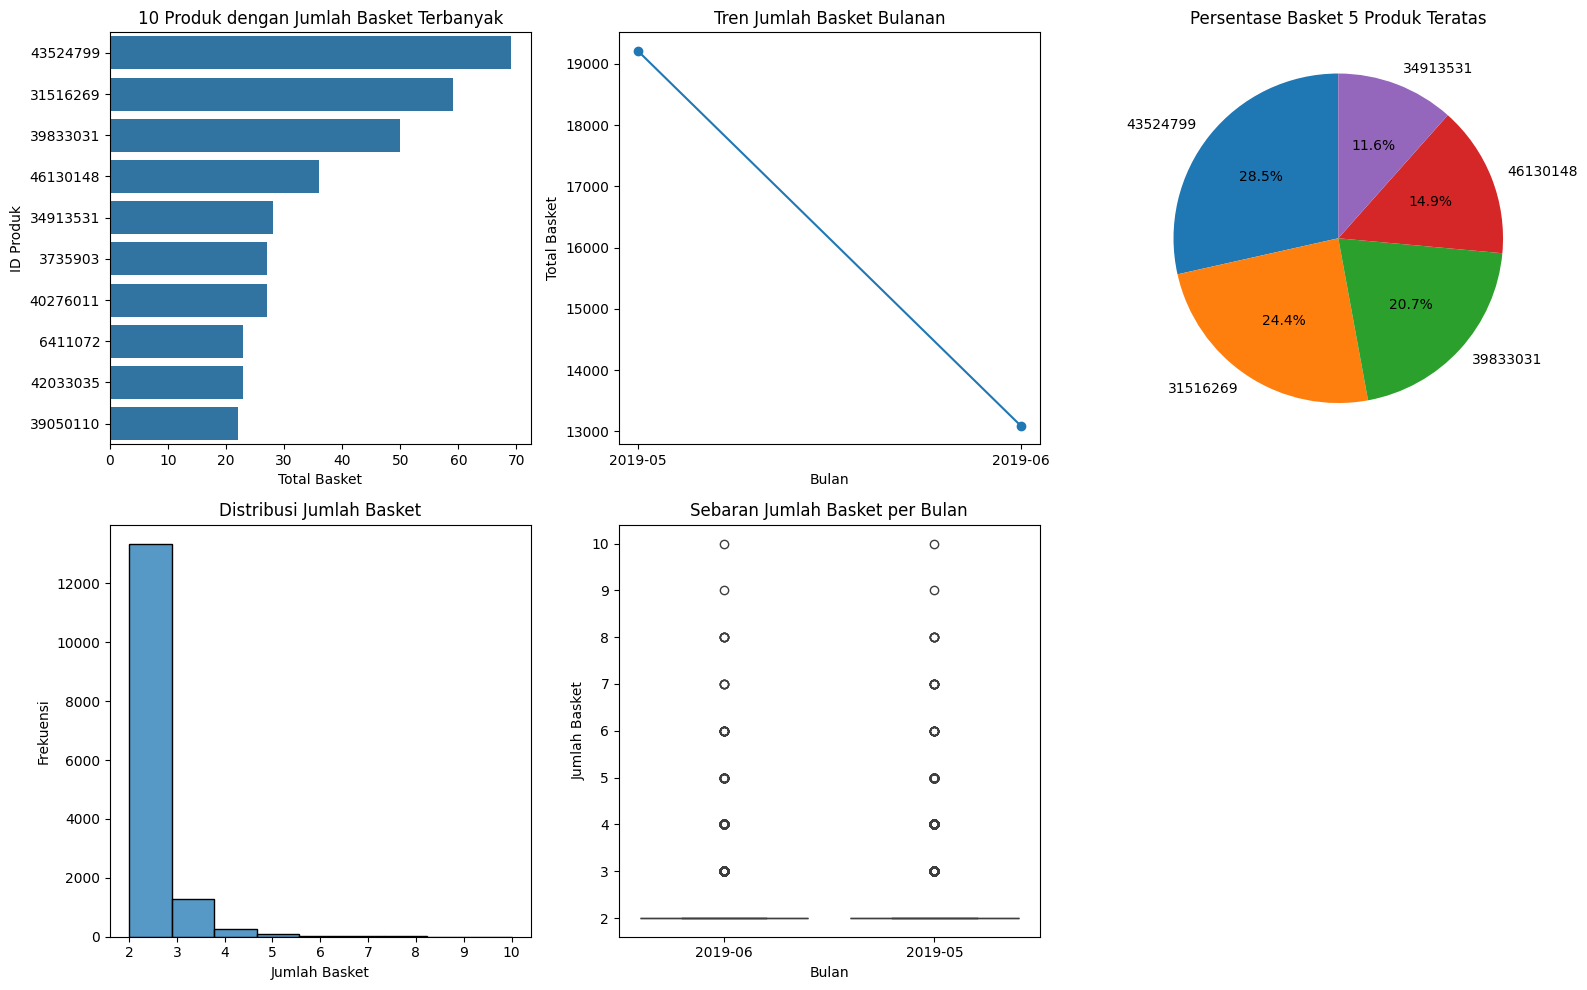

In [ ]:

#Tugas 6#
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('basket_details.csv')
df['basket_date'] = pd.to_datetime(df['basket_date'])
df['bulan'] = df['basket_date'].dt.to_period('M').astype(str)

# Menghitung total basket per produk
total_produk = df.groupby('product_id')['basket_count'].sum().sort_values(ascending=False).head(10)

# Menghitung tren basket bulanan
tren_bulanan = df.groupby('bulan')['basket_count'].sum()

# Menghitung 5 produk teratas untuk diagram lingkaran
pie_produk = df.groupby('product_id')['basket_count'].sum().nlargest(5)

# Membuat 5 grafik dalam satu tampilan
fig, axes = plt.subplots(2, 3, figsize=(16,10))

# Grafik 1: Barplot
sns.barplot(x=total_produk.values, y=total_produk.index.astype(str), ax=axes[0,0])
axes[0,0].set_title('10 Produk dengan Jumlah Basket Terbanyak')
axes[0,0].set_xlabel('Total Basket')
axes[0,0].set_ylabel('ID Produk')

# Grafik 2: Lineplot
axes[0,1].plot(tren_bulanan.index, tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Jumlah Basket Bulanan')
axes[0,1].set_xlabel('Bulan')
axes[0,1].set_ylabel('Total Basket')

# Grafik 3: Histogram
sns.histplot(df['basket_count'], bins=9, ax=axes[1,0])
axes[1,0].set_title('Distribusi Jumlah Basket')
axes[1,0].set_xlabel('Jumlah Basket')
axes[1,0].set_ylabel('Frekuensi')

# Grafik 4: Boxplot
sns.boxplot(data=df, x='bulan', y='basket_count', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah Basket per Bulan')
axes[1,1].set_xlabel('Bulan')
axes[1,1].set_ylabel('Jumlah Basket')

# Grafik 5: Pie Chart
axes[0,2].pie(
    pie_produk.values,
    labels=pie_produk.index.astype(str),
    autopct='%1.1f%%',
    startangle=90
)
axes[0,2].set_title('Persentase Basket 5 Produk Teratas')

# Menghilangkan grafik kosong
axes[1,2].axis('off')

plt.tight_layout()
plt.show()


Analisis: Berdasarkan kelima grafik, produk ID 43524799 memiliki jumlah basket tertinggi. Aktivitas basket paling tinggi terjadi pada Mei 2019 dan mengalami penurunan pada Juni 2019. Mayoritas data memiliki jumlah basket sebanyak 2. Diagram lingkaran juga menunjukkan bahwa kontribusi jumlah basket dari setiap produk teratas berbeda-beda.